# TRABAJO Parte 2: AIA_2025-2026

# Nombre y DNI del alumno/a 1: Adrián García Muñoz - 29556135P
# Nombre y DNI del alumno/a 2: Angela Catilla López - 53588681S

# Transfer Learning con CNNs - Dataset: Flowers

La idea de este trabajo es familiarizarnos con dos situaciones muy habituales en la actividad real de un "Machine Learning Engineer":

1.   En primer lugar, con una de las técnicas más potentes asociadas con las redes neuronales: el **Transfer Learning**. Dado que las redes neuronales, para resolver un problema, capturan en su estructura de capas y pesos una representación jerárquica del problema.
Entonces..., ¿por que no aprovechar ese conocimiento obtenido, para resolver otro problema diferente?

2.  En segundo lugar, con la **busqueda de información sobre conceptos nuevos**. En este caso, los dos primeros modelos a implementar los hemos trabajado en clase. No así el Transfer Learning, y por tanto, debereis buscar vosotros mismos como hacer lo que se pide para el Modelo 3. Consultar en blogs, web y tutoriales es algo común en el día a día de alguien que quiere profundizar en el ML y, para ello, existen infinidad de fuentes. A modo de ejemplo, una fuente para profundizar en el Transfer Learning con redes convolucionales es: https://www.learndatasci.com/tutorials/hands-on-transfer-learning-keras/

En este trabajo vamos intentar resolver un problema de clasificación sobre un dataset propuesto por Tensorflow en 2019 conocido como "flowers". Este conjunto está formado por 3670 imágenes de flores pertenecientes a 5 clases diferentes. Para ello implementaremos 3 modelos:

*   Modelo 1: implementación de una CNN básica.
*   Modelo 2: es una evolución del modelo anterior, aplicando técnicas que reduzcan el overfitting.
*   Modelo 3: rompemos la barrera de tener que seguir complicando nuestro modelo y se pide aplicar transfer learning utilizando un pre-trained model.





# a) Carga de datos

In [3]:
import tensorflow as tf
from tensorflow import keras

import numpy as np
import pandas as pd

import pathlib
import os
import glob
import shutil
tf.__version__

'2.21.0'

In [4]:
import warnings
warnings.filterwarnings('ignore')

Descargamos el dataset que pone a nuestra disposición Tensorflow.

In [27]:
_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

zip_file = tf.keras.utils.get_file(origin=_URL,
                                   fname="flower_photos.tgz",
                                   extract=True,
                                   )

base_dir = os.path.join(os.path.dirname(zip_file), 'flower_photos')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Tras completar la descarga, debemos tener la siguiente estructura de directorios:  

<pre style="font-size: 10.0pt; font-family: Arial; line-height: 2; letter-spacing: 1.0pt;" >
<b>~/.keras/datasets/flower_photos_extracted/flower_photos</b>
|__ <b>daisy</b>
|__ <b>dandelion</b>
|__ <b>roses</b>
|__ <b>sunflowers</b>
|__ <b>tulips</b>
</pre>

Desgraciadamente, para este dataset, Tensorflow no nos proporciona la estructura de directorios necesaria de train y de validación. Por lo que debemos proceder del siguiente modo:

* Crear una carpeta `train` y de `val`, cada una de ellas debe contener a su vez, cinco subdirectorios: uno para cada clase de flor.
* Moveremos las imágenes de las carpetas originales a estas nuevas carpetas. De modo que el 80% de las imágenes vayan al conjunto de train y el 20% restante al de validación.
* La estructura final de directorios debe ser la siguiente:

<pre style="font-size: 10.0pt; font-family: Arial; line-height: 2; letter-spacing: 1.0pt;" >
<b>~/.keras/datasets/flower_photos_extracted/flower_photos</b>
|__ <b>train</b>
    |______ <b>daisy</b>: [12.jpg, 28.jpg, 31.jpg ....]
    |______ <b>dandelion</b>: [41.jpg, 22.jpg, 35.jpg ....]
    |______ <b>roses</b>: [121.jpg, 92.jpg, 38.jpg ....]
    |______ <b>sunflowers</b>: [93.jpg, 23.jpg, 83.jpg ....]
    |______ <b>tulips</b>: [109.jpg, 267.jpg, 93.jpg ....]
 |__ <b>val</b>
    |______ <b>daisy</b>: [507.jpg, 508.jpg, 509.jpg ....]
    |______ <b>dandelion</b>: [719.jpg, 720.jpg, 721.jpg ....]
    |______ <b>roses</b>: [514.jpg, 515.jpg, 516.jpg ....]
    |______ <b>sunflowers</b>: [560.jpg, 561.jpg, 562.jpg .....]
    |______ <b>tulips</b>: [640.jpg, 641.jpg, 642.jpg ....]
</pre>

Creamos una lista con el nombre de las 5 clases. En castellano sería: margaritas, diente de león, rosas, girasoles y tulipanes.

In [5]:
classes = ['roses', 'daisy', 'dandelion', 'sunflowers', 'tulips']

Creemos la estructura de directorios necesaria:

In [6]:
base_dir = os.path.expanduser("~/.keras/datasets/flower_photos_extracted/flower_photos/")

Preparamos variables con las rutas de los diferentes directorios a crear:

In [7]:
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')

daisy_dir = os.path.join(train_dir, 'daisy')
dandelion_dir = os.path.join(train_dir, 'dandelion')
roses_dir = os.path.join(train_dir, 'roses')
sunflowers_dir = os.path.join(train_dir, 'sunflowers')
tulips_dir = os.path.join(train_dir, 'tulips')

In [31]:
SPLIT_RATIO=0.8

for cl in classes:
    # path de las imagenes de la clase cl
    img_path = os.path.join(base_dir, cl)

    # obtenemos la lista de todas las imagenes
    images = glob.glob(img_path + '/*.jpg')
    print("{}: {} Imagenes".format(cl, len(images)))

    # determinamos cuantas imagenes son el 80%
    num_train = int(round(len(images)*SPLIT_RATIO))

    # separamos las imagenes en dos listas
    train, val = images[:num_train], images[num_train:]

    # creamos la carpeta de train/clase y val/clase
    if not os.path.exists(os.path.join(base_dir, 'train', cl)):
        os.makedirs(os.path.join(base_dir, 'train', cl))
    else:
        shutil.rmtree(os.path.join(base_dir, 'train', cl))

    if not os.path.exists(os.path.join(base_dir, 'val', cl)):
        os.makedirs(os.path.join(base_dir, 'val', cl))
    else:
        shutil.rmtree(os.path.join(base_dir, 'val', cl))

    for t in train:
        shutil.move(t, os.path.join(base_dir, 'train', cl))

    for v in val:
        shutil.move(v, os.path.join(base_dir, 'val', cl))


roses: 641 Imagenes
daisy: 633 Imagenes
dandelion: 898 Imagenes
sunflowers: 699 Imagenes
tulips: 799 Imagenes


**Tarea 1: Muestre el nombre de dos ficheros cualquiera en alguna de esas rutas**

In [8]:
import random

imagenes = os.listdir(sunflowers_dir)
print(random.choice(imagenes))
print(random.choice(imagenes))




19349582128_68a662075e_n.jpg
5067864967_19928ca94c_m.jpg


Es decir, la clase a la que pertenece cada imagen no viene dada por el nombre del fichero sino por el directorio en el que se encuentra almacenada.

**Tarea 2: Muestra el número de imágenes de train que tenemos de cada clase**

In [9]:
for dir in classes:
    print(dir + ": " + str(len(os.listdir(train_dir + "/"+dir))))

roses: 513
daisy: 506
dandelion: 718
sunflowers: 559
tulips: 639


# b) Visualización del dataset

**Tarea 3: Muestra 3 imágenes de cada una de las clases, el título de la imagen será el shape del array de numpy asociado a la imagen**

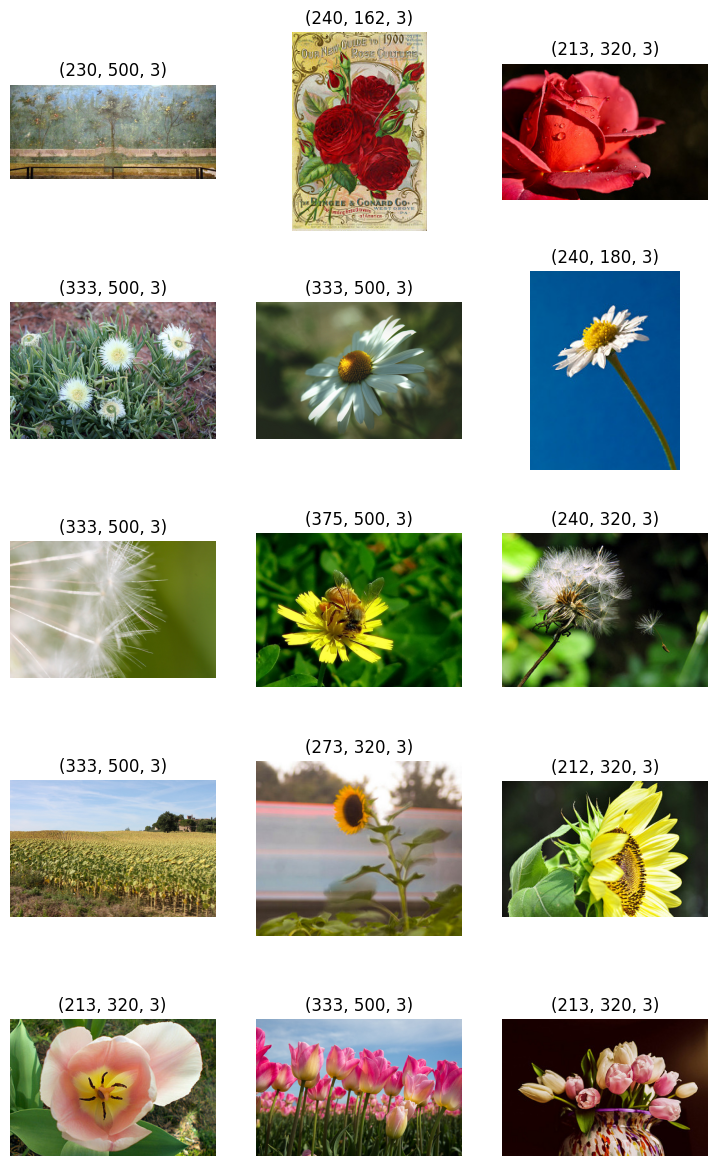

In [12]:
from keras.preprocessing import image
import matplotlib.pyplot as plt

filas = len(classes)
columnas = 3
plt.figure(figsize=(columnas * 3, filas * 3))

idx = 1
for clase in classes:
    ruta = train_dir + "/" + clase
    imagenes = os.listdir(ruta)
    for i in range(0, 3):
        imagen = random.choice(imagenes)
        img = image.load_img(ruta + "/" + imagen)
        img_array = image.img_to_array(img)
        plt.subplot(len(classes), 3, idx)

        plt.imshow(img_array.astype("uint8"))
        plt.axis("off")

        plt.title(img_array.shape)

        idx += 1


plt.show()

        

# c) Modelo 1: CNN básica (objetivo: accuracy_valid > 60%)


Implemente una red convolucional para resolver el problema de clasificación. Para ello se sugiere una CNN con 3 capas convolucionales + pooling con la siguiente estructura:

Bloque de procesamiento de imagen:
1.   32 kernels -> 64 kernels -> 96 kernels
2.   kernels de 3x3.
3.   Stride = 1 y padding = SI.
4.   Función de activación ReLU.
5.   Maxpooling de 2x2 con stride clásico de 2 pixeles.
6.   Igualamos el tamaño de todas las imágenes a 150 x 150.

Bloque de decisión:
7.   Capa densa de 512 neuronas.
8.   Capa densa de salida.

**Tarea 4: Define un modelo con la estructura anterior**

In [13]:
from tensorflow.keras import layers, models

num_clases = len(classes)

model = models.Sequential([
    # Bloque 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same',
                  input_shape=(150,150,3)), # 150 x 150 x 3 -> Se iguala el tamaño de las imagenes y al ser RGB se asignan 3 canales
    layers.MaxPooling2D((2,2)),

    # Bloque 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    # Bloque 3
    layers.Conv2D(96, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    # Bloque de decisión
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(num_clases, activation='softmax')
])

**Tarea 5: Indica el shape de la imagen antes y después de cada capa de la red. Explica cómo has obtenido dichos valores**

|Capa| Shape a la salida| #parámetros |
|:-|:-:|:-:|
|Conv_1|150 x 150 x 32|896
|Pool_1|75 x 75 x 32|0
|Conv_2|75 x 75 x 64|18.496
|Pool_2|37 x 37 x 64|0
|Conv_3|37 x 37 x 96|55.392
|Pool_3|18 x 18 x 96|0
|flatten|31.104|0
|densa_1|512|15.925.760
|salida|5|2.565


Para calcular los shapes de salida de las **capas convolucionales**, al tener padding y stride = 1, la anchura y altura no cambian, tan solo cambian los canales al número de kernels que tenga la capa. En cuanto a los parámetros, hay que multiplicar un número *x* por los canales de la capa. Este número *x* se obtiene de la multiplicación de la anchura y altura del kernel de la capa más 1 (el parámetro bias). Por otro lado, para calcular el shape de salida de las capas de **pooling**, tan solo hay que reducir la altura y la anchura a la mitad, ya que el kernel de estas es 2x2. En este caso, las capas de pooling no tienen parámetros porque no aprenden nada.


Para el **bloque de decisión**, exceptuando la capa de *flatten*, que no aprende tampoco parámetros y cuyo shape es aplanar el anterior (multiplicar 18 x 18 x 96), los demás shapes son el número de neuronas de cada capa. Por otro lado, los parámetros son calculados como el shape de la capa anterior más uno, multiplicado por el número de neuronas de la capa actual.



**Tarea 6: Compara el resultado con un summary() del modelo**

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 96)     │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 31104)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    15,925,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,003,109 (61.05 MB)

 Trainable params: 16,003,109 (61.05 MB)

 Non-trainable params: 0 (0.00 B)

**Tarea 7: Entrena el modelo de manera que obtenga un accuracy (sobre el conjunto de validación) > 60%.**

* Utilice el optimizador que considere más adecuado.
*   Recuerda que si no se realiza conversión a One-Hot de la etiqueta a predecir, debes utilizar como función de error `SparseCategoricalCrossentropy` (este es el procedimiento que hemos usado en clase).
*   Considera un learning rate en el entorno de 0.001.
*   En el caso de los generators utiliza `class_mode='sparse'`.
*   Puedes utilizar p.e. un `batch_size = 100`.

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

train_datagen = ImageDataGenerator(rescale=1/255)
val_datagen   = ImageDataGenerator(rescale=1/255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150,150),
    batch_size=100,
    class_mode='sparse'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(150,150),
    batch_size=100,
    class_mode='sparse'
)



model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

loss, acc = model.evaluate(val_generator)
print("Accuracy validación:", acc)


Found 2935 images belonging to 5 classes.
Found 735 images belonging to 5 classes.
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 628ms/step - accuracy: 0.3182 - loss: 1.9454 - val_accuracy: 0.5034 - val_loss: 1.2039
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 612ms/step - accuracy: 0.5315 - loss: 1.1353 - val_accuracy: 0.5823 - val_loss: 1.0547
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - accuracy: 0.6361 - loss: 0.9465 - val_accuracy: 0.6190 - val_loss: 0.9614
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 574ms/step - accuracy: 0.6964 - loss: 0.7930 - val_accuracy: 0.6435 - val_loss: 0.9316
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 580ms/step - accuracy: 0.7693 - loss: 0.6367 - val_accuracy: 0.6694 - val_loss: 0.9092
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 583ms/step - accuracy: 0.8204 - loss: 0.4903 - val_accuracy: 0.6395 - val_loss: 1.1003
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 581ms/step - accuracy: 0.8583 - loss: 0.3939 - val_accuracy: 0.6327 - val_loss: 1.1201
Epoch 8/20
30/

**Tarea 8: Muestra la evolución de la función de error (train y valid) durante el entrenamiento.Explica que problema presenta el modelo que hemos entrenado.**

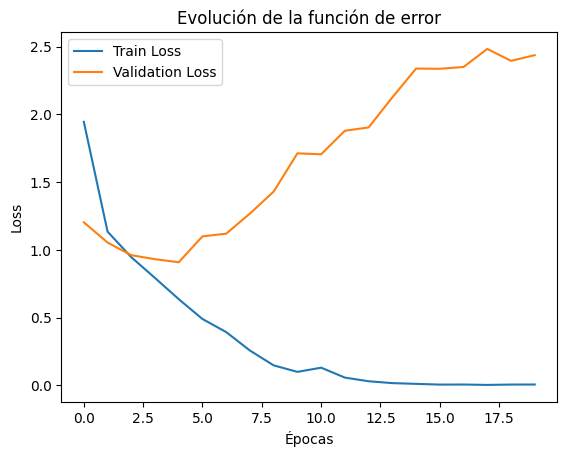

In [16]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(train_loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.title('Evolución de la función de error')
plt.show()

El modelo presenta un claro *overfitting* a partir del tercer epoch, ya que aprende demasiado el conjunto de entrenamiento, impidiendo generalizar.

# d) Modelo 2: reducción del overfitting (objetivo: accuracy_valid > 70%)

Para mejorar el accuracy del modelo, vamos a incorporar las dos técnicas más habituales de reducción del overfitting:

    * drop-out
    * data augmentation
    

**Tarea 9: Explica en que consisten y qué utilidad tienen para nuestro problema**





El **drop-out** consiste en no entrenar un porcentaje aleatorio de neuronas en el sistema para que así no aprenda patrones específicos del conjunto de entrenamiento, es decir, haya menos *overfitting* en nuestro problema.

Por otro lado, la técnica de **data augmentation** consiste en generar nuevos datos de entrenamiento a partir de los datos existentes (manteniendo su clasificación), modificándolos de distintas formas para que nuestro modelo pueda aprender más a partir de los mismos datos y también se reduzca el *overfitting*.

**Tarea 10: Construye un nuevo modelo 2 incorporando (en el modelo 1 anterior) el dropout adecuado**

In [ ]:
model2 = models.Sequential([
    # Bloque 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same',
                  input_shape=(150,150,3)), # 150 x 150 x 3 -> Se iguala el tamaño de las imagenes y al ser RGB se asignan 3 canales
    layers.MaxPooling2D((2,2)),

    # Bloque 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    # Bloque 3
    layers.Conv2D(96, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    # Bloque de decisión
    layers.Flatten(),

    layers.Dropout(0.5),

    layers.Dense(512, activation='relu'),
    layers.Dense(num_clases, activation='softmax')
])

**Tarea 11: Explica que tipos de augmentation vas a considerar y que utilidad tienen en nuestro problema de clasificacion**

Se van a utilizar los siguientes tipos de augmentation:

- **Rotación**:  Se rotan las imágenes para que el modelo aprenda a reconocer las flores aunque no estén alineadas.
- **Desplazamiento (width_shift_range y height_shift_range)**: Se desplazan las imágenes tanto horizontal como verticalmente para que el modelo no dependa de la posición exacta de la flor, además de que lo hace más resistente a variaciones de encuadre.
- **Zoom**: Se añade o quita zoom para que el modelo pueda identificar la flor aunque esté cerca o lejos.
- **Flip horizontal**: Se invierte la imagen horizontalmente para tener nuevos ejemplos. En nuestro caso es útil ya que la clasificación no depende de la orientación de la imagen.

**Tarea 12: Entrena el modelo de manera que obtenga un accuracy (sobre el conjunto de validación) > 70%.**

In [28]:
train_datagen2 = ImageDataGenerator(
    rescale=1/255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True
)

train_generator2 = train_datagen2.flow_from_directory(
    train_dir,
    target_size=(150,150),
    batch_size=100,
    class_mode='sparse'
)

model2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    train_generator2,
    validation_data=val_generator,
    epochs=20
)

loss, acc = model2.evaluate(val_generator)
print("Accuracy validación:", acc)


Found 2935 images belonging to 5 classes.
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 25s 782ms/step - accuracy: 0.3428 - loss: 1.5853 - val_accuracy: 0.4735 - val_loss: 1.2687
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 734ms/step - accuracy: 0.5063 - loss: 1.1668 - val_accuracy: 0.6109 - val_loss: 1.0674
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 705ms/step - accuracy: 0.5945 - loss: 1.0194 - val_accuracy: 0.6095 - val_loss: 1.0216
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 23s 748ms/step - accuracy: 0.6174 - loss: 0.9749 - val_accuracy: 0.6327 - val_loss: 0.9569
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 23s 770ms/step - accuracy: 0.6204 - loss: 0.9422 - val_accuracy: 0.6993 - val_loss: 0.8543
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 708ms/step - accuracy: 0.6463 - loss: 0.8980 - val_accuracy: 0.6803 - val_loss: 0.8595
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 706ms/step - accuracy: 0.6596 - loss: 0.8751 - val_accuracy: 0.7102 - val_loss: 0.7903
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 705ms/step - 

**Tarea 13: Muestra la evolucion de la funcion de error durante el entrenamiento. Explica qué diferencias de comportamiento hay entre las gráficas del modelo 1 y el modelo 2**

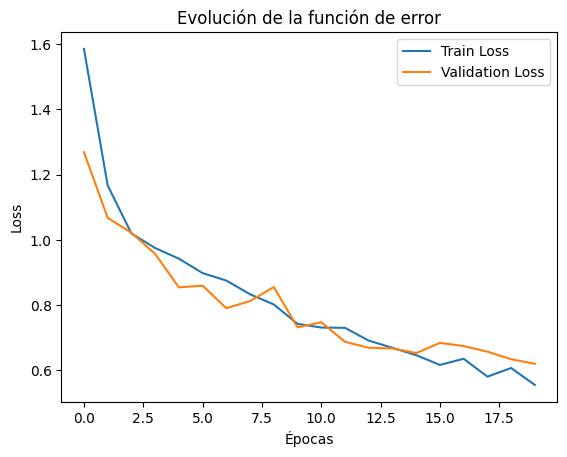

In [29]:
train_loss2 = history2.history['loss']
val_loss2 = history2.history['val_loss']

plt.plot(train_loss2, label='Train Loss')
plt.plot(val_loss2, label='Validation Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.title('Evolución de la función de error')
plt.show()

La diferencia de esta gráfica con la anterior es muy visual. La pérdida en validación en el modelo 1 crecía a partir del tercer epoch, ya que el modelo memorizaba los datos (*overfitting*). Sin embargo, ahora en el modelo 2, al haber utilizado técnicas para combatir el overfitting, la pérdida en validación disminuye, por lo que se intuye que el modelo 2 generaliza mucho mejor que el modelo 1.

# c) Modelo 3: Transfer Learning (objetivo: accuracy_valid > 88%)

En nuestro problema de clasificación de flores, el utilizar CNNs diseñadas y entrenadas por nosotros mismos, aparece una barrera en las proximidades del 75-77% de precisión del modelo (siempre sobre validación).

Para superar este escollo, el siguiente paso natural es la utilización de modelos preentrenados. Existe una gran variedad de ellos basados en redes CNNs clásicas, donde la principal diferencia es que acumulan más capas que nuestros modelos 1 y 2. Adicionalmente, en estos modelos se han ido incorporando diferentes propuestas para mejorar la arquitectura de la CNN.

En general, utilizando estos modelos convolucionales preentrenados podemos alcanzar accuracies próximos al 90%. Normalmente, estos modelos han sido previamente entrenados sobre datasets de gran tamaño y con gran número de categorías. P.e. en subconjuntos de Imagenet (14 millones de imagenes de 22K categorías).

Dado que estos modelos se entrenaron para resolver un problema "relativamente" parecido a nuestro problema de clasificación, parece razonable pensar que podemos aprovechar ese conocimiento capturado en la red para resolver nuestro problema de clasificación de flores.



Para elegir el modelo preentrenado que debe utilizar cada grupo, proceda del siguiente modo:
* Paso 1: sume los DNIs de los componentes del grupo (si el grupo tiene un sólo miembro, vaya directamente al paso 2). res = dni_1 + dn_2
* Paso 2: Aplique la siguiente operación al resultado anterior: res mod 6.
* Paso 3: Tome el modelo cuyo número asociado coincide con el resultado de la operación anterior.
* Paso 4: El porcentaje que aparece entre paréntesis junto al nombre del modelo es el accuracy (en validación) que deberías poder alcanzar sin dificultad utilizando el modelo. En todos los casos considera un input_shape = (224, 224, 3).

  0. Resnet50 (>90%)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet50/ResNet50

  1. Resnet101 (>90%) input_shape = (224, 224, 3)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/ResNet101

  2. VGG16 (>90%) input_shape = (224, 224, 3)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg16/VGG16

  3. VGG19 (>90%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg19/VGG19

  4. Xception (>88%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/xception/Xception

  5. Inceptionv3 (>88%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/inception_v3/InceptionV3

P.e. si los DNIs de los alumnos son: 12345678 y 23456781. La suma es 35802459. De donde 35802459 mod 6 = 3. Por tanto, tomaríamos el modelo VGG16.

Recuerda que puedes utilizar el siguiente post como referencia del uso de transfer learning: https://www.learndatasci.com/tutorials/hands-on-transfer-learning-keras/

**Tarea 14: Importa el modelo desde Tensorflow**

Dado que este modelo ha sido entrenado para clasificar entre 1.000 categorías, las capas densas finales del modelo no son útiles para nuestro problema de clasificación de 5 categorías (es lo que suele llamarse include_top = SI/NO). De manera que eliminamos lo que a veces se suele llamar el "top model". De este modo sólo nos quedamos con la parte que hace la funcionalidad de "procesamiento" de la imagen.

In [59]:
model_vgg16 = tf.keras.applications.VGG16(
    include_top=False,
    weights='imagenet',
    input_tensor=None,
    input_shape=(224,224,3),
    pooling=None,
    classes=1000,
    classifier_activation='softmax'
)

# Se congelan todas las capas para la tarea 16

for layer in model_vgg16.layers:
    layer.trainable = False




**Tarea 15: Personalizar el bloque de decisión**  
Añadimos una capa de flatten y tres nuevas capas densas especificas para nuestro problema con dimensiones 4096, 1072 y la que necesite la capa de salida (con sus correspondientes drop-outs).

In [60]:
# Número 2: VGG16
from tensorflow.keras import Model

model_aux = model_vgg16.output
model_aux= layers.Flatten()(model_aux)

model_aux = layers.Dense(4096, activation='relu')(model_aux)
model_aux= layers.Dropout(0.5)(model_aux)

model_aux = layers.Dense(1072, activation='relu')(model_aux)
model_aux = layers.Dropout(0.5)(model_aux)

output = layers.Dense(num_clases, activation='softmax')(model_aux)

model3 = Model(inputs=model_vgg16.input, outputs=output)


**Tarea 16: Congelar los pesos que no se vayan a entrenar**

Previo a hacer el denominado `Fine-Tuning` del modelo, indicaremos a Tensorflow que únicamente debe entrenar:

   * Las dos últimas capas convolucionales de la red preentrenada, de las que realizaremos un ajuste fino de los pesos.
   * Las tres capas densas que hemos incluido nuevas.

In [61]:
# Se descongelan las ultimas 2 capas de vgg16 (las capas densas añadidas ya están descongeladas)
model_vgg16.get_layer('block5_conv3').trainable = True
model_vgg16.get_layer('block5_conv2').trainable = True


**Tarea 17: Crear los datagenerators oportunos**

Para ello:
> * Utiliza Data augmentation.  
> * Las imágenes tienen que ser preprocesadas igual que cuando se entrenó el modelo pre.entrenado original. Para ello se utiliza el parámetro `preprocessing_function=preprocess_input` (preprocess_input importado desde `keras.applications.xxxxxx` en ambos generators (train y valid). Por tanto, no hay que indicarle `rescale`. En caso de ser necesario, se encargará `preprocess_input`.  
> * Dado que estamos reutilizando un modelo que no "es nuestro", deberemos ceñirnos al tamaño de imagen que permite la red a la entrada. Recuerda que debe ser: 224x224.

In [62]:
from tensorflow.keras.applications.vgg16 import preprocess_input

train_datagen3 = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    preprocessing_function=preprocess_input
)

val_datagen3 = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator3 = train_datagen3.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='sparse'
)

val_generator3 = val_datagen3.flow_from_directory(
    val_dir,
    target_size=(224,224),
    batch_size=32,
    class_mode='sparse'
)

Found 2935 images belonging to 5 classes.
Found 735 images belonging to 5 classes.


**Tarea 18: Haz el fine-tuning del modelo con el objetivo de alcanzar un accuracy (sobre el conjunto de validación > 88%).**

A la hora de entrenar un modelo pretrained es típico bajar el learning rate respecto al que utilizaríamos para un modelo nuestro desde cero.

In [63]:
model3.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history3 = model3.fit(
    train_generator3,
    validation_data=val_generator3,
    epochs=40
)

loss, acc = model3.evaluate(val_generator3)
print("Accuracy validación:", acc)

Epoch 1/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.3761 - loss: 10.8543 - val_accuracy: 0.6925 - val_loss: 1.5766
Epoch 2/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 307s 3s/step - accuracy: 0.5244 - loss: 4.7257 - val_accuracy: 0.7565 - val_loss: 1.2067
Epoch 3/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 422s 5s/step - accuracy: 0.5853 - loss: 3.0696 - val_accuracy: 0.7714 - val_loss: 1.0186
Epoch 4/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 454s 5s/step - accuracy: 0.6153 - loss: 2.5200 - val_accuracy: 0.7918 - val_loss: 0.9174
Epoch 5/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 389s 4s/step - accuracy: 0.6613 - loss: 1.9120 - val_accuracy: 0.7918 - val_loss: 0.8352
Epoch 6/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 305s 3s/step - accuracy: 0.6845 - loss: 1.5220 - val_accuracy: 0.7959 - val_loss: 0.7783
Epoch 7/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.7141 - loss: 1.3451 - val_accuracy: 0.8122 - val_loss: 0.7040
Epoch 8/40
92/92 ━━━━━━━━━━━━━━━━━━━━ 247s 3s/step - accuracy: 0.7244 - loss: 1.2098 - val_accuracy: 0.8150 - 